## Hello_Word

In [2]:
from typing import Dict, TypedDict
from langgraph.graph import StateGraph

In [3]:
class AgentState(TypedDict):
    message : str

def greeting_node(state : AgentState) -> AgentState:

    state['message'] = "Hello " + state['message'] + ", how is your day going?"

    return state



In [4]:
graph = StateGraph(AgentState)

graph.add_node("greeter", greeting_node)
graph.set_entry_point("greeter")
graph.set_finish_point("greeter")

app = graph.compile()



In [5]:
result = app.invoke({"message" : "Nam"})
print(result)

{'message': 'Hello Nam, how is your day going?'}


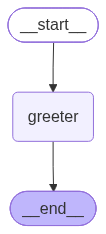

In [6]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

##  Conditional_Agent


In [2]:
from typing import TypedDict, List
from langgraph.graph import StateGraph, START,END

In [3]:
class AgentState(TypedDict):
    number1 : int
    operation : str
    number2 : int
    finalNumber : int


def adder(state : AgentState):
    state['finalNumber'] = state['number1'] + state['number2']
    return state

def subtractor(state : AgentState):
    state['finalNumber']= state['number1'] - state['number2']
    return state

def decide_next_node(state : AgentState):
    if state['operation'] == "+":
        return "addition_operation"
    elif state['operation'] == "-":
        return "subtraction_operation"



In [4]:
graph = StateGraph(AgentState)

graph.add_node("add_node",adder)
graph.add_node("subtract_node",subtractor)
graph.add_node("router",lambda state:state)

graph.add_edge(START,"router")

graph.add_conditional_edges(
    "router",
    decide_next_node,

    {
        "addition_operation" : "add_node",
        "subtraction_operation" : "subtract_node"
    }
)

graph.add_edge("add_node",END)
graph.add_edge("subtract_node",END)

app = graph.compile()


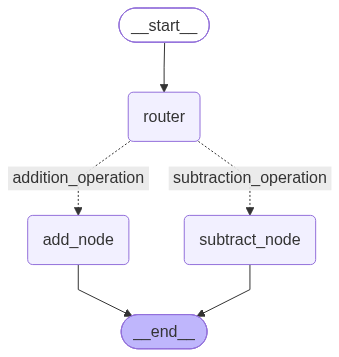

In [5]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

In [6]:
inital_state_1 = AgentState(number1 = 10, operation = "+" , number2 = 5)
print(app.invoke(inital_state_1))

{'number1': 10, 'operation': '+', 'number2': 5, 'finalNumber': 15}


## Loop_Agent

In [31]:
from typing import TypedDict, List
from langgraph.graph import StateGraph,START,END
import random

In [32]:
class AgentState(TypedDict):
    name : str
    number : List[int]
    counted : int

In [33]:
def greeting_node(state : AgentState):
    state['name'] = f"Hi there, {state['name']}"
    state['counted'] = 0
    return state

def random_node(state : AgentState):
    state['number'].append(random.randint(0,10))
    state['counted'] += 1
    return state

def should_continue(state : AgentState):
    if state['counted'] > 5:
        return 'exit'
    else:
        return 'loop'


In [34]:
workflow = StateGraph(AgentState)

workflow.add_node("greeting", greeting_node)
workflow.add_node("random",random_node)

workflow.add_edge(START,"greeting")
workflow.add_edge("greeting","random")
workflow.add_conditional_edges(
    "random",
    should_continue,

    {
        "exit" : END,
        "loop" : "random"
    }
)
workflow.add_edge("random",END)

app1 = workflow.compile()

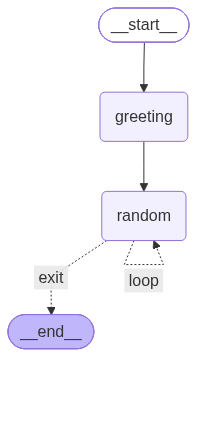

In [35]:
from IPython.display import Image, display

display(Image(app1.get_graph().draw_mermaid_png()))

In [36]:
inital_state_2 = AgentState(name = "Nam", number = [], counted = 0)
print(app1.invoke(inital_state_2))

{'name': 'Hi there, Nam', 'number': [3, 2, 7, 3, 4, 3], 'counted': 6}


## ReAct Agent



In [1]:
from typing import TypedDict, Annotated, Sequence
from langchain_core.messages import BaseMessage, ToolMessage, SystemMessage
from langgraph.graph.message import add_messages
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
import os
from dotenv import load_dotenv
from langgraph.prebuilt import ToolNode
from langgraph.graph import StateGraph, END
load_dotenv()

class AgentState(TypedDict):
    message : Annotated[Sequence[BaseMessage], add_messages]

@tool
def add(a : int, b : int):
    """Cộng 2 số """
    return a + b

tools = [add]

model = llm = ChatOpenAI(
        base_url=os.getenv("ROUTER_BASE_URL", "http://localhost:20128/v1"),
        api_key=os.getenv("ROUTER_API_KEY", "none"),
        model=os.getenv("JUDGE_MODEL_NAME", "rag-judge-combo"),
        temperature=0.0,
        max_retries=3
    ).bind_tools(tools)

def model_call(state : AgentState):
    system_msg = SystemMessage(
        content="Bạn là trợ lý AI của tôi, đưa ra cho tôi câu trả lời tốt nhất."
    )
    respone = model.invoke([system_msg] + state["message"])
    return {"message" : [respone]}

def should_continue(state : AgentState):
    last_message = state["message"][-1]
    if not last_message.tool_calls:
        return "end"
    else:
        return "continue"


graph = StateGraph(AgentState)
graph.add_node("our_agent",model_call)

tool_node = ToolNode(tools = tools)
graph.add_node("tools",tool_node)

graph.set_entry_point("our_agent")

graph.add_conditional_edges(
    "our_agent",
    should_continue,

    {
        "end" : END,
        "continue" : "tools"
    }
)

graph.add_edge("tools","our_agent")

app = graph.compile()

def print_stream(stream):
    for s in stream:
        message = s["message"][-1]
        if isinstance(message,tuple):
            print(message)
        else:
            message.pretty_print()


inputs = {"message" : [("user","Add 3 + 4")]}
print_stream(app.stream(inputs,stream_mode="values"))



================================ Human Message =================================

Add 3 + 4


APIConnectionError: Connection error.